Universidad del Valle de Guatemala  
Departamento de Ciencias de la Computación  
CC2017 Modelación y Simulación

# 02. Agentes en red. Clientes y boca a boca

En el notebook 01 la demanda era una curva fija. Aquí se obtiene de una población de clientes potenciales, cada uno modelado como un agente. Los agentes están conectados en una red de contactos y se recomiendan la cafetería entre sí, como en el modelo de difusión de Bass.

Cada mes un agente inactivo se vuelve cliente con probabilidad $1 - e^{-(p + q f)}$. El coeficiente $p$ representa la atracción por publicidad, $q$ el boca a boca y $f$ la fracción de sus contactos que ya son clientes. Cada cliente activo visita el negocio según su propia tasa y al final del mes puede abandonarlo según su propia probabilidad.

## 1. Parámetros de la población

Los valores de `CustomerParams` son supuestos. Se ajustaron para que las visitas promedio se parezcan a la demanda del notebook 01.

In [1]:
import sys
from dataclasses import replace

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

sys.path.append("../src")
from business_sim.customers import CustomerPopulation, simulate_customers
from business_sim.finance import demand_curve, months_survived, seasonal_factor, simulate_finance
from business_sim.params import BusinessParams, CustomerParams

p = BusinessParams()
cp = CustomerParams()
season = seasonal_factor(p)
pd.Series(vars(cp)).to_frame("Valor")

,Valor
population,1200.000
neighbors,8.000
rewiring,0.100
initial_customers,290.000
innovation,0.005
imitation,0.250
mean_visits,2.000
visits_shape,2.000
mean_churn,0.080
churn_concentration,20.000


La población es de 1 200 clientes potenciales, de los cuales 290 son clientes desde la apertura.

## 2. Red de contactos y heterogeneidad

Se usa una red Watts-Strogatz, que reproduce dos rasgos de las redes sociales. Los conocidos de una persona suelen conocerse entre sí (agrupamiento alto) y cualquier par de personas está a pocos pasos de distancia. Las visitas siguen una distribución gamma y el abandono una distribución beta, por lo que cada agente es distinto.

Nodos = 1200, aristas = 4800
Grado promedio = 8.00
Agrupamiento = 0.471


Distancia promedio = 5.20


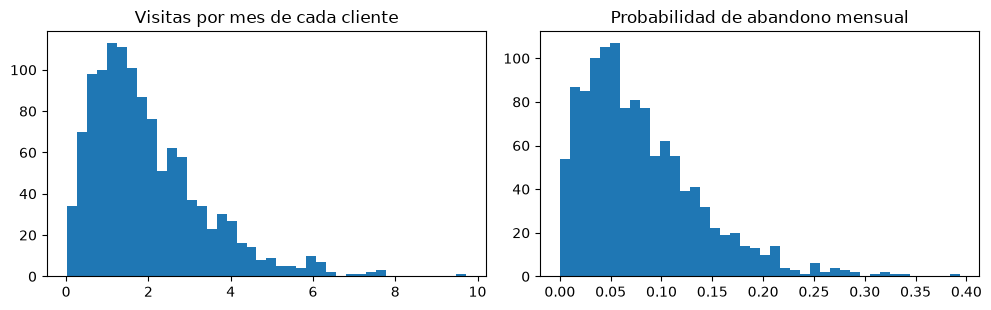

Visitas: media = 1.97, mediana = 1.64, máx = 9.73
Abandono: media = 0.080, p5 = 0.011, p95 = 0.195


In [2]:
pop = CustomerPopulation(cp, rng=1)
G = pop.graph
print(f"Nodos = {G.number_of_nodes()}, aristas = {G.number_of_edges()}")
print(f"Grado promedio = {2 * G.number_of_edges() / G.number_of_nodes():.2f}")
print(f"Agrupamiento = {nx.average_clustering(G):.3f}")
print(f"Distancia promedio = {nx.average_shortest_path_length(G):.2f}")

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.2))
ejes[0].hist(pop.visit_rate, bins=40)
ejes[0].set_title("Visitas por mes de cada cliente")
ejes[1].hist(pop.churn, bins=40)
ejes[1].set_title("Probabilidad de abandono mensual")
plt.tight_layout()
plt.show()
print(f"Visitas: media = {pop.visit_rate.mean():.2f}, mediana = {np.median(pop.visit_rate):.2f}, máx = {pop.visit_rate.max():.2f}")
print(f"Abandono: media = {pop.churn.mean():.3f}, p5 = {np.quantile(pop.churn, 0.05):.3f}, p95 = {np.quantile(pop.churn, 0.95):.3f}")

Cada persona tiene 8 contactos. El agrupamiento es de 0.471 y la distancia promedio entre dos personas es de 5.20 pasos. La media de visitas es de 1.97 por mes, la mitad de los agentes visita menos de 1.64 veces y el máximo es de 9.73. La probabilidad de abandono mensual promedia 8 % y va de 1.1 % a 19.5 % entre el 5 % y el 95 % de los agentes.

## 3. Una corrida

Se simulan 24 meses con la misma estacionalidad del notebook 01.

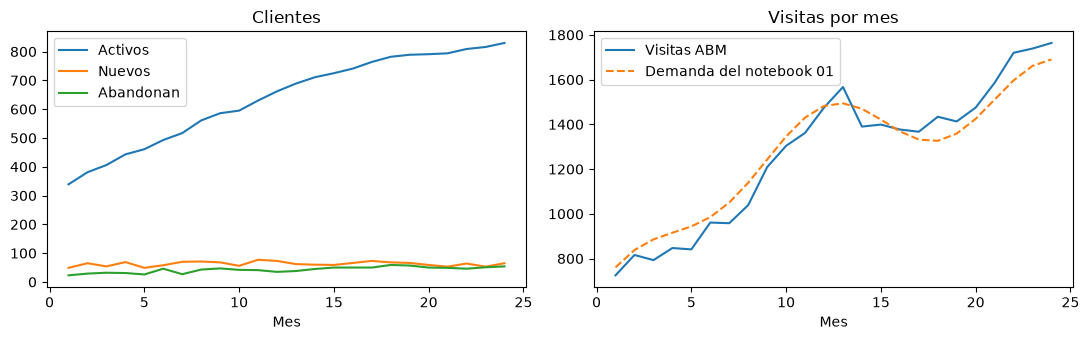

,active,new,visits,churned
month,,,,
1,339,49,725,23
6,493,58,961,46
12,662,73,1475,35
18,782,68,1434,59
24,830,65,1764,54


In [3]:
una = simulate_customers(cp, season, rng=1)

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
ejes[0].plot(una.index, una["active"], label="Activos")
ejes[0].plot(una.index, una["new"], label="Nuevos")
ejes[0].plot(una.index, una["churned"], label="Abandonan")
ejes[0].set_xlabel("Mes")
ejes[0].set_title("Clientes")
ejes[0].legend()
ejes[1].plot(una.index, una["visits"], label="Visitas ABM")
ejes[1].plot(una.index, demand_curve(p), "--", label="Demanda del notebook 01")
ejes[1].set_xlabel("Mes")
ejes[1].set_title("Visitas por mes")
ejes[1].legend()
plt.tight_layout()
plt.show()
una.loc[[1, 6, 12, 18, 24]]

Los clientes activos pasan de 339 en el mes 1 a 830 en el mes 24. Los nuevos clientes se mantienen entre 49 y 77 por mes, mientras los abandonos suben de 31 por mes en el primer semestre a 51 en el último, porque hay más clientes que pueden irse. Las visitas siguen la forma de la demanda del notebook 01, con picos en los meses 12 y 13 y caída entre los meses 14 y 18.

## 4. Variabilidad entre réplicas

El resultado cambia de una corrida a otra por el azar en adopción, visitas y abandono. Se repite la simulación 30 veces con semillas distintas.

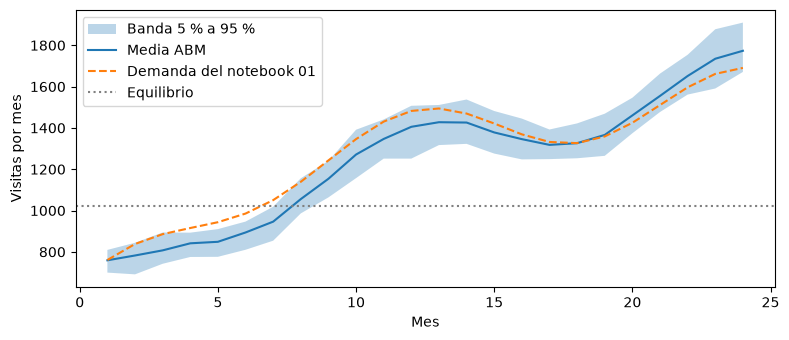

Error absoluto medio contra el notebook 01 = 58 visitas


,Media,p5,p95
1,759.0,700.0,810.0
6,894.0,810.0,947.0
12,1405.0,1251.0,1507.0
24,1773.0,1671.0,1910.0


In [4]:
N_REP = 30


def replicas(cparams, n=N_REP, semilla=100):
    """Devuelve la matriz (réplicas x meses) de visitas y la de activos."""
    corridas = [simulate_customers(cparams, season, rng=semilla + i) for i in range(n)]
    return np.array([c["visits"] for c in corridas]), np.array([c["active"] for c in corridas])


visitas, activos = replicas(cp)
meses = np.arange(1, p.horizon + 1)
plt.figure(figsize=(8, 3.5))
plt.fill_between(meses, *np.quantile(visitas, [0.05, 0.95], axis=0), alpha=0.3, label="Banda 5 % a 95 %")
plt.plot(meses, visitas.mean(axis=0), label="Media ABM")
plt.plot(meses, demand_curve(p), "--", label="Demanda del notebook 01")
plt.axhline(p.breakeven_customers, color="gray", ls=":", label="Equilibrio")
plt.xlabel("Mes")
plt.ylabel("Visitas por mes")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Error absoluto medio contra el notebook 01 = {np.abs(visitas.mean(axis=0) - demand_curve(p)).mean():.0f} visitas")
pd.DataFrame({
    "Media": visitas.mean(axis=0), "p5": np.quantile(visitas, 0.05, axis=0), "p95": np.quantile(visitas, 0.95, axis=0)
}, index=meses).loc[[1, 6, 12, 24]].round(0)

La media de las réplicas se aleja en promedio 58 visitas por mes de la demanda del notebook 01. Queda por debajo en los meses 2 a 17 y por encima desde el mes 19. En el mes 24 la banda entre el 5 % y el 95 % va de 1 671 a 1 910 visitas. Las visitas promedio superan el equilibrio desde el mes 8.

## 5. Boca a boca, retención y supervivencia

Se comparan cuatro casos. En cada réplica las visitas del ABM se usan como demanda en `simulate_finance` del notebook 01, para medir cuántos meses aguanta la caja.

In [5]:
casos = {
    "Base": cp,
    "Sin boca a boca (q = 0)": replace(cp, imitation=0.0),
    "Abandono 5 %": replace(cp, mean_churn=0.05),
    "Abandono 12 %": replace(cp, mean_churn=0.12),
}
resumen = {}
for nombre, c in casos.items():
    v, a = replicas(c)
    meses_vivo = [months_survived(simulate_finance(p, fila)) for fila in v]
    resumen[nombre] = {
        "Activos mes 24": a[:, -1].mean(),
        "Visitas mes 12": v[:, 11].mean(),
        "Visitas mes 24": v[:, -1].mean(),
        "Meses que aguanta (media)": np.mean(meses_vivo),
        "Réplicas que llegan al mes 24": np.mean(np.array(meses_vivo) == p.horizon),
    }
pd.DataFrame(resumen).round(2)

,Base,Sin boca a boca (q = 0),Abandono 5 %,Abandono 12 %
Activos mes 24,807.43,144.30,949.90,581.10
Visitas mes 12,1405.37,384.90,1681.93,1067.23
Visitas mes 24,1773.37,322.07,2089.13,1278.63
Meses que aguanta (media),24.00,4.00,24.00,15.03
Réplicas que llegan al mes 24,1.00,0.00,1.00,0.40


Sin boca a boca los clientes activos bajan a 144 en el mes 24 y el negocio aguanta 4 meses en todas las réplicas. Con el abandono base de 8 % y con 5 % todas las réplicas llegan al mes 24. Con un abandono de 12 % los activos del mes 24 bajan a 581, el negocio aguanta 15.03 meses en promedio y solo el 40 % de las réplicas llega al mes 24.

## Conclusión

La población de agentes reproduce la demanda del notebook 01 a partir de reglas individuales y agrega su variabilidad. El siguiente notebook incorpora la capacidad de atención, que limita cuántas de esas visitas se convierten en ventas.